In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/justmarkham/pydata-dc-2016-tutorial/master/sms.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("\nFirst 5 messages:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nSpam and Ham count:")
print(df["label"].value_counts())

Dataset loaded successfully!

First 5 messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape:
(5572, 2)

Spam and Ham count:
label
ham     4825
spam     747
Name: count, dtype: int64


In [2]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate messages
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Convert labels into numerical values
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("\nDataset after preprocessing:")
print(df.head())

print("\nFinal dataset shape:", df.shape)

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Dataset after preprocessing:
  label                                            message  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0

Final dataset shape: (5169, 3)


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Input features and target labels
X = df["message"]
y = df["label_num"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into numerical features
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

Training messages: 4135
Testing messages: 1034
Training feature matrix: (4135, 7414)
Testing feature matrix: (1034, 7414)


In [4]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict on test data
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Model Trained Successfully!")
print(f"\nAccuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["HAM", "SPAM"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Model Trained Successfully!

Accuracy: 96.71%

Classification Report:
              precision    recall  f1-score   support

         HAM       0.96      1.00      0.98       903
        SPAM       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034


Confusion Matrix:
[[903   0]
 [ 34  97]]


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict on test data
y_pred_lr = lr_model.predict(X_test_tfidf)

# Evaluate the model
print("Logistic Regression Model Trained Successfully!")

print(f"\nAccuracy: {accuracy_score(y_test, y_pred_lr) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["HAM", "SPAM"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Model Trained Successfully!

Accuracy: 95.65%

Classification Report:
              precision    recall  f1-score   support

         HAM       0.95      1.00      0.98       903
        SPAM       0.98      0.67      0.80       131

    accuracy                           0.96      1034
   macro avg       0.97      0.83      0.89      1034
weighted avg       0.96      0.96      0.95      1034


Confusion Matrix:
[[901   2]
 [ 43  88]]


In [6]:
def predict_message(message):
    # Convert the input message using the trained TF-IDF vectorizer
    message_tfidf = tfidf.transform([message])

    # Predict using the trained Naive Bayes model
    prediction = nb_model.predict(message_tfidf)[0]

    # Get prediction probabilities
    probabilities = nb_model.predict_proba(message_tfidf)[0]

    if prediction == 1:
        result = "SPAM"
    else:
        result = "HAM"

    print("Message:", message)
    print("Prediction:", result)
    print(f"HAM probability: {probabilities[0] * 100:.2f}%")
    print(f"SPAM probability: {probabilities[1] * 100:.2f}%")

# Test examples
predict_message("Congratulations! You have won a free prize. Call now!")
print()
predict_message("Hey, are we meeting for lunch today?")

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
HAM probability: 15.22%
SPAM probability: 84.78%

Message: Hey, are we meeting for lunch today?
Prediction: HAM
HAM probability: 99.75%
SPAM probability: 0.25%


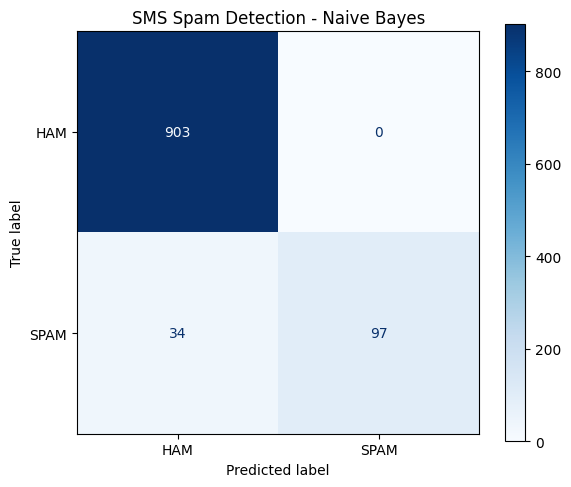

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrix visualization
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    display_labels=["HAM", "SPAM"],
    cmap="Blues",
    ax=ax
)

plt.title("SMS Spam Detection - Naive Bayes")
plt.tight_layout()
plt.show()

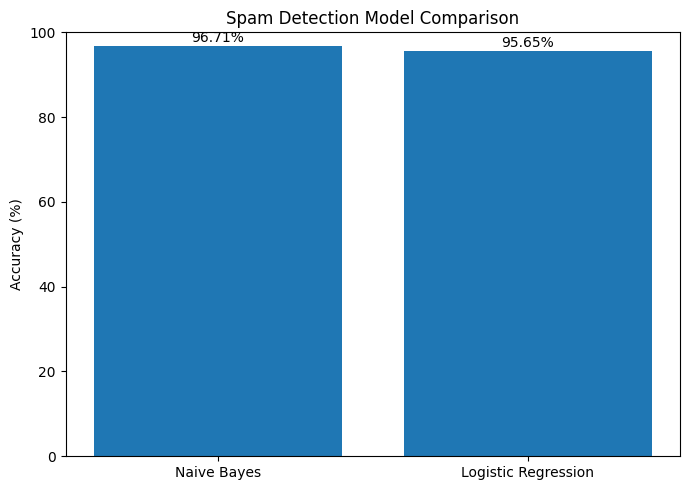

In [8]:
models = ["Naive Bayes", "Logistic Regression"]

accuracies = [
    accuracy_score(y_test, y_pred_nb) * 100,
    accuracy_score(y_test, y_pred_lr) * 100
]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies)

plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Spam Detection Model Comparison")

for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [9]:
import joblib
import os

# Create a folder for saved models
os.makedirs("spam_detection_model", exist_ok=True)

# Save trained model and TF-IDF vectorizer
joblib.dump(
    nb_model,
    "spam_detection_model/naive_bayes_model.pkl"
)

joblib.dump(
    tfidf,
    "spam_detection_model/tfidf_vectorizer.pkl"
)

print("Model and vectorizer saved successfully!")
print(os.listdir("spam_detection_model"))

Model and vectorizer saved successfully!
['naive_bayes_model.pkl', 'tfidf_vectorizer.pkl']


In [11]:
# Load the saved files
loaded_model = joblib.load(
    "spam_detection_model/naive_bayes_model.pkl"
)

loaded_tfidf = joblib.load(
    "spam_detection_model/tfidf_vectorizer.pkl"
)

# Test a new message
message = ["URGENT! Claim your free reward now"]

message_features = loaded_tfidf.transform(message)
prediction = loaded_model.predict(message_features)[0]

if prediction == 1:
    print("Prediction: SPAM")
else:
    print("Prediction: HAM")

Prediction: SPAM


In [12]:
import shutil

shutil.make_archive(
    "spam_detection_model",
    "zip",
    "spam_detection_model"
)

print("ZIP file created successfully!")

ZIP file created successfully!
